In [306]:
import pandas as pd
import sqlite3

conn = sqlite3.connect("../data/checking-logs.sqlite")

In [307]:
views = pd.io.sql.read_sql(
"""
--sql
        SELECT count(*) as views, date(datetime) as date
        FROM pageviews 
        WHERE uid like 'user_%'
        GROUP BY date   ORDER By date
        """, conn)
views.head()

,views,date
0,1,2020-04-17
1,23,2020-04-18
2,15,2020-04-19
3,3,2020-04-21
4,1,2020-04-22


In [308]:
# tables = pd.read_sql_query("SELECT name FROM sqlite_master WHERE type='table';", conn)
# tables

In [309]:
cheks = pd.io.sql.read_sql(
"SELECT * FROM checker where uid not like 'admin_%' ", conn)
cheks.head()

,index,status,success,timestamp,numTrials,labname,uid
0,7,ready,0,2020-04-17 05:19:02.744528,1,project1,user_4
1,8,checking,0,2020-04-17 05:22:35.249331,2,project1,user_4
2,9,ready,1,2020-04-17 05:22:45.549397,2,project1,user_4
3,10,checking,1,2020-04-17 05:34:14.691200,3,project1,user_4
4,11,ready,1,2020-04-17 05:34:24.422370,3,project1,user_4


In [310]:
commits = pd.io.sql.read_sql(
"""
--sql
SELECT count(*) AS commits, date(timestamp) AS date 
FROM checker WHERE uid not LIKE 'admin_%' 
GROUP BY date   ORDER BY date""", 
conn)

commits.head()

,commits,date
0,23,2020-04-17
1,69,2020-04-18
2,33,2020-04-19
3,25,2020-04-20
4,25,2020-04-21


In [ ]:
viewsAndCommits = pd.io.sql.read_sql(
"""SELECT views, commits, comms.date as date FROM 
(SELECT count(*) as views, date(datetime) as date
        FROM pageviews 
        WHERE uid like 'user_%'
        GROUP BY date) AS views
JOIN 
(SELECT count(*) AS commits, date(timestamp) AS date 
FROM checker WHERE uid not LIKE 'admin_%' 
GROUP BY date) AS comms
ON views.date = comms.date ORDER BY date
""", conn)
# viewsAndCommits.head()
# viewsAndCommits.shape
viewsAndCommits.info()


<class 'pandas.DataFrame'>
RangeIndex: 32 entries, 0 to 31
Data columns (total 3 columns):
 #   Column   Non-Null Count  Dtype
---  ------   --------------  -----
 0   views    32 non-null     int64
 1   commits  32 non-null     int64
 2   date     32 non-null     str  
dtypes: int64(2), str(1)
memory usage: 900.0 bytes


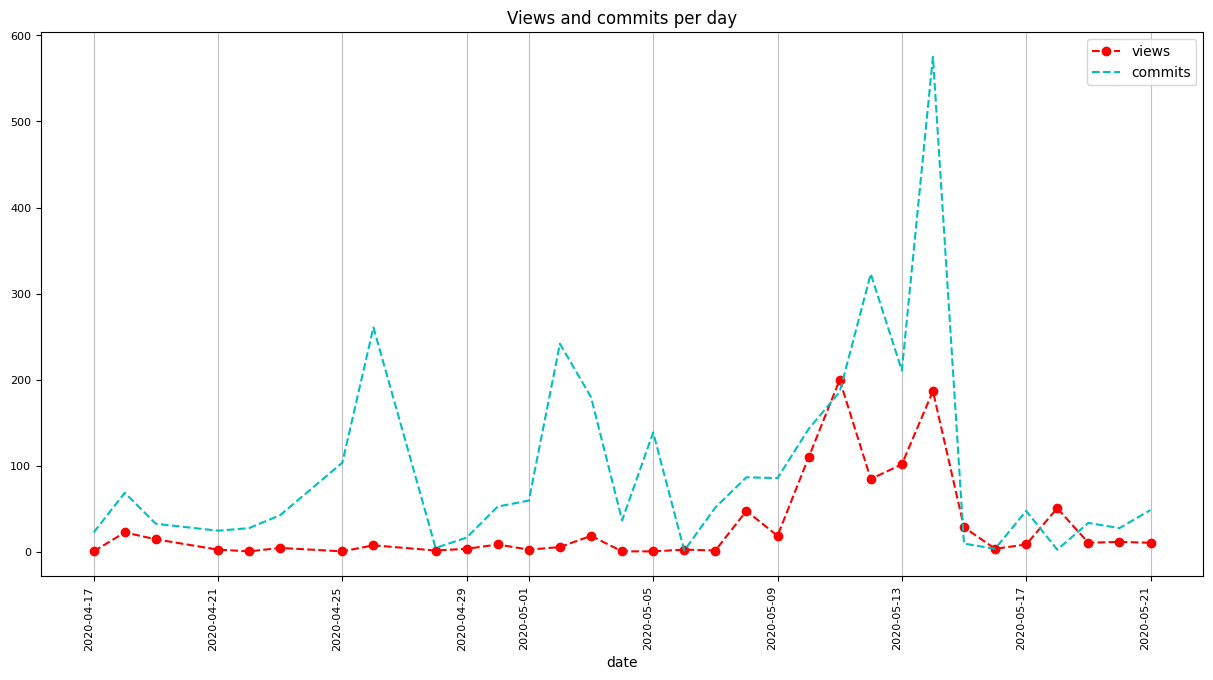

In [312]:
viewsAndCommits["date"] = viewsAndCommits["date"].astype("datetime64[ns]")
pl = viewsAndCommits.plot(
    x='date', 
    y=['views', 'commits'], 
    title='Views and commits per day', 
    rot=90, 
    fontsize=8,
    figsize=(15, 8),
    style=['r--o', 'c--']
)
pl.grid(axis='x', color='gray', alpha=0.5);


In [313]:
count = len(viewsAndCommits.loc[viewsAndCommits['views'] > 150])
# count = viewsAndCommits.loc[viewsAndCommits['views'] > 150]['views'].count()
count

2

### Сколько раз число просмотров превышало 150?
Ответ: 2

In [314]:
conn.close()